In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from scipy.stats import (
    chi2_contingency,
    ttest_ind,
    mannwhitneyu,
    pointbiserialr,
)

DATA_PATH = Path(
    "../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

df.head()



Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
#Clean TotalCharges
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print(
    "Missing TotalCharges:",
    df["TotalCharges"].isna().sum()
)

Missing TotalCharges: 11


In [3]:
#statistical test
df_statistics = df.dropna(
    subset=["TotalCharges"]
).copy()

In [4]:
#Encode Churn - statistical analysis
df_statistics["ChurnEncoded"] = (
    df_statistics["Churn"]
    .map({
        "No": 0,
        "Yes": 1,
    })
)

In [5]:
#Descriptive Statistics
numerical_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
]

statistics_summary = pd.DataFrame({
    "Mean": (
        df_statistics[
            numerical_columns
        ].mean()
    ),
    "Median": (
        df_statistics[
            numerical_columns
        ].median()
    ),
    "Variance": (
        df_statistics[
            numerical_columns
        ].var()
    ),
    "StdDev": (
        df_statistics[
            numerical_columns
        ].std()
    ),
    "Min": (
        df_statistics[
            numerical_columns
        ].min()
    ),
    "Max": (
        df_statistics[
            numerical_columns
        ].max()
    ),
})

statistics_summary

,Mean,Median,Variance,StdDev,Min,Max
tenure,32.421786,29.000,6.024698e+02,24.545260,1.00,72.00
MonthlyCharges,64.798208,70.350,9.051658e+02,30.085974,18.25,118.75
TotalCharges,2283.300441,1397.475,5.138252e+06,2266.771362,18.80,8684.80


In [6]:
#Statistics by churn
churn_statistics = (
    df_statistics
    .groupby("Churn")[
        [
            "tenure",
            "MonthlyCharges",
            "TotalCharges",
        ]
    ]
    .agg([
        "mean",
        "median",
        "std",
        "var",
    ])
)

churn_statistics

tenure                               MonthlyCharges         \
            mean median        std         var           mean median   
Churn                                                                  
No     37.650010   38.0  24.076940  579.699064      61.307408  64.45   
Yes    17.979133   10.0  19.531123  381.464768      74.441332  79.65   

                             TotalCharges                                      
             std         var         mean   median          std           var  
Churn                                                                          
No     31.094557  966.871469  2555.344141  1683.60  2329.456984  5.426370e+06  
Yes    24.666053  608.414183  1531.796094   703.55  1890.822994  3.575212e+06

In [7]:
#categorical vs categorical
contract_table = pd.crosstab(
    df_statistics["Contract"],
    df_statistics["Churn"]
)

contract_table

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1306,166
Two year,1637,48


In [8]:
chi2, p_value, dof, expected = (
    chi2_contingency(contract_table)
)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"Degrees of freedom: {dof}")

Chi-square statistic: 1179.5458
P-value: 0.000000
Degrees of freedom: 2


In [9]:
#Interpretation
alpha = 0.05

if p_value < alpha:
    print(
        "Reject H0: Contract type and churn "
        "are statistically associated."
    )
else:
    print(
        "Fail to reject H0: No statistically "
        "significant association was detected."
    )

Reject H0: Contract type and churn are statistically associated.


In [10]:
#Continuous variable vs binary target
tenure_churn = df_statistics.loc[
    df_statistics["Churn"] == "Yes",
    "tenure",
]

tenure_no_churn = df_statistics.loc[
    df_statistics["Churn"] == "No",
    "tenure",
]

print(
    "Mean tenure - churn:",
    tenure_churn.mean()
)

print(
    "Mean tenure - retained:",
    tenure_no_churn.mean()
)

Mean tenure - churn: 17.979133226324237
Mean tenure - retained: 37.65000968429208


In [11]:
#Independent t-test
t_stat, p_value = ttest_ind(
    tenure_churn,
    tenure_no_churn,
    equal_var=False,
)

print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print(
        "Reject H0: Mean tenure differs "
        "significantly between churn groups."
    )
else:
    print(
        "Fail to reject H0."
    )

T-statistic: -34.9719
P-value: 0.000000
Reject H0: Mean tenure differs significantly between churn groups.


In [12]:
#MonthlyCharges
monthly_churn = df_statistics.loc[
    df_statistics["Churn"] == "Yes",
    "MonthlyCharges",
]

monthly_retained = df_statistics.loc[
    df_statistics["Churn"] == "No",
    "MonthlyCharges",
]

t_stat, p_value = ttest_ind(
    monthly_churn,
    monthly_retained,
    equal_var=False,
)

print(
    "Mean MonthlyCharges - churn:",
    monthly_churn.mean()
)

print(
    "Mean MonthlyCharges - retained:",
    monthly_retained.mean()
)

print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.6f}")

Mean MonthlyCharges - churn: 74.44133226324237
Mean MonthlyCharges - retained: 61.307408483439865
T-statistic: 18.3409
P-value: 0.000000


In [13]:
#TechSupport vs Churn
tech_support_table = pd.crosstab(
    df_statistics["TechSupport"],
    df_statistics["Churn"]
)

chi2, p_value, dof, expected = (
    chi2_contingency(
        tech_support_table
    )
)

print(tech_support_table)

print(f"\nChi-square: {chi2:.4f}")
print(f"P-value: {p_value:.6f}")

Churn                  No   Yes
TechSupport                    
No                   2026  1446
No internet service  1407   113
Yes                  1730   310

Chi-square: 824.9256
P-value: 0.000000


In [14]:
#Payment Method vs Churn
payment_table = pd.crosstab(
    df_statistics["PaymentMethod"],
    df_statistics["Churn"]
)

chi2, p_value, dof, expected = (
    chi2_contingency(
        payment_table
    )
)

print(payment_table)

print(f"\nChi-square: {chi2:.4f}")
print(f"P-value: {p_value:.6f}")

Churn                        No   Yes
PaymentMethod                        
Bank transfer (automatic)  1284   258
Credit card (automatic)    1289   232
Electronic check           1294  1071
Mailed check               1296   308

Chi-square: 645.4299
P-value: 0.000000


In [15]:
#Point-biserial correlation
correlation_results = []

for feature in [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
]:

    correlation, p_value = (
        pointbiserialr(
            df_statistics["ChurnEncoded"],
            df_statistics[feature],
        )
    )

    correlation_results.append({
        "Feature": feature,
        "Correlation": correlation,
        "PValue": p_value,
    })

correlation_df = pd.DataFrame(
    correlation_results
)

correlation_df

,Feature,Correlation,PValue
0,tenure,-0.354049,9.437650e-207
1,MonthlyCharges,0.192858,6.760843e-60
2,TotalCharges,-0.199484,4.876866e-64


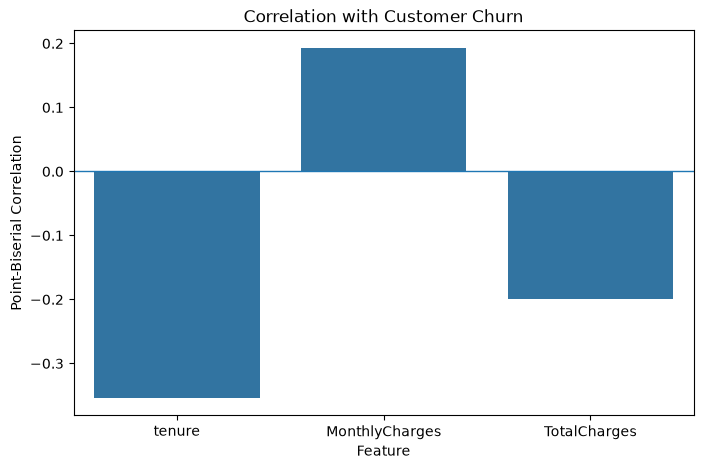

In [16]:
#Visualize correlations
plt.figure(
    figsize=(8, 5)
)

sns.barplot(
    data=correlation_df,
    x="Feature",
    y="Correlation",
)

plt.axhline(
    0,
    linewidth=1
)

plt.title(
    "Correlation with Customer Churn"
)

plt.ylabel(
    "Point-Biserial Correlation"
)

plt.show()

In [17]:
contract_chi2, contract_p_value, _, _ = (
    chi2_contingency(
        contract_table
    )
)

tenure_t, tenure_p_value = ttest_ind(
    tenure_churn,
    tenure_no_churn,
    equal_var=False,
)

monthly_t, monthly_p_value = ttest_ind(
    monthly_churn,
    monthly_retained,
    equal_var=False,
)

tech_chi2, tech_p_value, _, _ = (
    chi2_contingency(
        tech_support_table
    )
)

payment_chi2, payment_p_value, _, _ = (
    chi2_contingency(
        payment_table
    )
)

In [18]:
#statistical hypotheses
hypothesis_results = []
def interpret_p_value(
    p_value: float,
    alpha: float = 0.05,
) -> str:

    if p_value < alpha:
        return "Statistically Significant"

    return "Not Statistically Significant"

hypothesis_results = pd.DataFrame([
    {
        "Hypothesis": "Contract vs Churn",
        "Test": "Chi-square",
        "Statistic": contract_chi2,
        "PValue": contract_p_value,
    },
    {
        "Hypothesis": "Tenure vs Churn",
        "Test": "Welch's t-test",
        "Statistic": tenure_t,
        "PValue": tenure_p_value,
    },
    {
        "Hypothesis": "Monthly Charges vs Churn",
        "Test": "Welch's t-test",
        "Statistic": monthly_t,
        "PValue": monthly_p_value,
    },
    {
        "Hypothesis": "Tech Support vs Churn",
        "Test": "Chi-square",
        "Statistic": tech_chi2,
        "PValue": tech_p_value,
    },
    {
        "Hypothesis": "Payment Method vs Churn",
        "Test": "Chi-square",
        "Statistic": payment_chi2,
        "PValue": payment_p_value,
    },
])

hypothesis_results["Significant"] = (
    hypothesis_results["PValue"] < 0.05
)

hypothesis_results.round(6)

,Hypothesis,Test,Statistic,PValue,Significant
0,Contract vs Churn,Chi-square,1179.545829,0.0,True
1,Tenure vs Churn,Welch's t-test,-34.971870,0.0,True
2,Monthly Charges vs Churn,Welch's t-test,18.340919,0.0,True
3,Tech Support vs Churn,Chi-square,824.925564,0.0,True
4,Payment Method vs Churn,Chi-square,645.429900,0.0,True
